In [1]:
import os
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from io import BytesIO

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
%pip install -q prophet

In [3]:
url = "https://raw.githubusercontent.com/facebook/prophet/main/examples/example_retail_sales.csv"

response = requests.get(url, timeout=30)
response.raise_for_status()

df = pd.read_csv(BytesIO(response.content))

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
display(df.head())
print("\nColumn names:")
print(df.columns.tolist())

Dataset loaded successfully!
Dataset shape: (293, 2)


,ds,y
0,1992-01-01,146376
1,1992-02-01,147079
2,1992-03-01,159336
3,1992-04-01,163669
4,1992-05-01,170068



Column names:
['ds', 'y']


In [4]:
# Display dataset information
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nFirst 5 rows:")
display(df.head())

print("\nMissing values:")
print(df.isnull().sum())

print("\nBasic statistical summary:")
display(df.describe(include="all"))

Dataset shape: (293, 2)

Column names:
['ds', 'y']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 293 entries, 0 to 292
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   ds      293 non-null    object
 1   y       293 non-null    int64 
dtypes: int64(1), object(1)
memory usage: 4.7+ KB

First 5 rows:


,ds,y
0,1992-01-01,146376
1,1992-02-01,147079
2,1992-03-01,159336
3,1992-04-01,163669
4,1992-05-01,170068



Missing values:
ds    0
y     0
dtype: int64

Basic statistical summary:


,ds,y
count,293,293.000000
unique,293,NaN
top,2016-05-01,NaN
freq,1,NaN
mean,NaN,308971.310580
std,NaN,86084.323897
min,NaN,146376.000000
25%,NaN,234503.000000
50%,NaN,314051.000000
75%,NaN,375795.000000


In [5]:
print("Available columns:", df.columns.tolist())

Available columns: ['ds', 'y']


In [6]:
print("Dataset shape:", df.shape)
print("Column names:", df.columns.tolist())
display(df.head())

Dataset shape: (293, 2)
Column names: ['ds', 'y']


,ds,y
0,1992-01-01,146376
1,1992-02-01,147079
2,1992-03-01,159336
3,1992-04-01,163669
4,1992-05-01,170068


In [7]:
df["ds"] = pd.to_datetime(df["ds"], errors="coerce")
df["y"] = pd.to_numeric(df["y"], errors="coerce")

df = df.dropna(subset=["ds", "y"])
df = df.sort_values("ds")

print("Cleaned dataset shape:", df.shape)
print("Date range:", df["ds"].min(), "to", df["ds"].max())
display(df.head())

Cleaned dataset shape: (293, 2)
Date range: 1992-01-01 00:00:00 to 2016-05-01 00:00:00


,ds,y
0,1992-01-01,146376
1,1992-02-01,147079
2,1992-03-01,159336
3,1992-04-01,163669
4,1992-05-01,170068


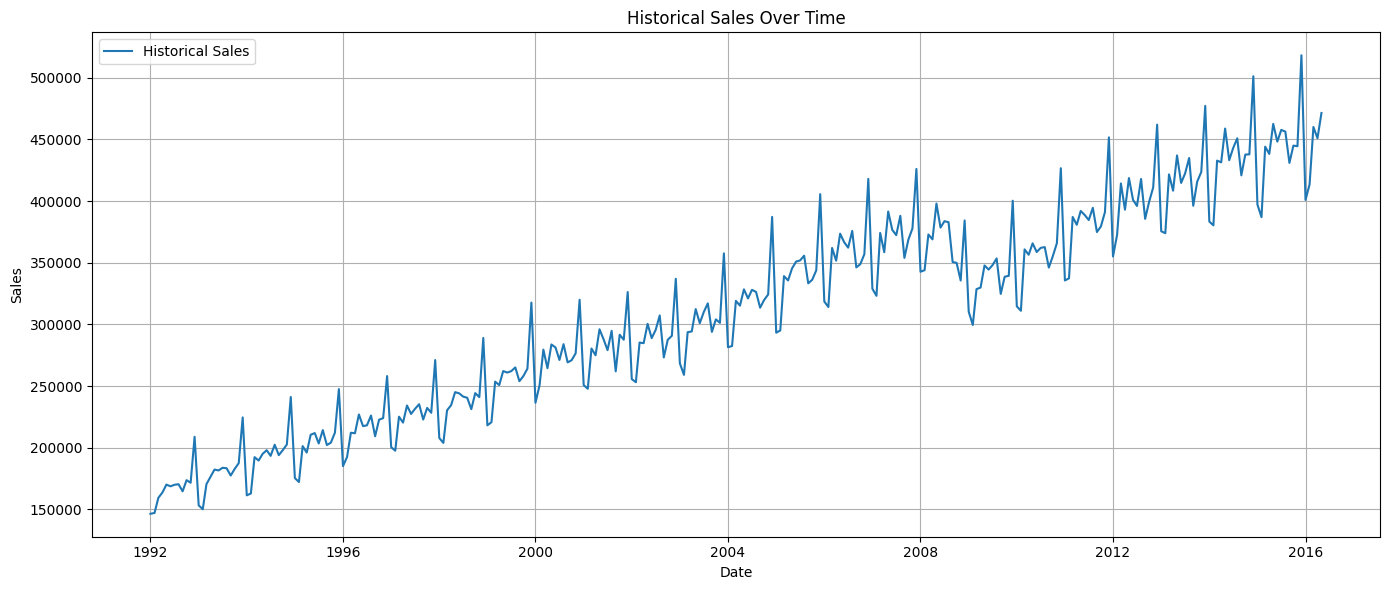

In [8]:
plt.figure(figsize=(14, 6))

plt.plot(df["ds"], df["y"], label="Historical Sales")

plt.title("Historical Sales Over Time")
plt.xlabel("Date")
plt.ylabel("Sales")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [9]:
from prophet import Prophet

model = Prophet(
    yearly_seasonality=True,
    weekly_seasonality=False,
    daily_seasonality=False
)

model.fit(df[["ds", "y"]])

print("Prophet model trained successfully!")

Prophet model trained successfully!


In [10]:
future = model.make_future_dataframe(periods=12, freq="MS")

forecast = model.predict(future)

display(
    forecast[["ds", "yhat", "yhat_lower", "yhat_upper"]].tail(12)
)

,ds,yhat,yhat_lower,yhat_upper
293,2016-06-01,467188.345347,456185.966473,477747.140292
294,2016-07-01,468248.724215,458809.847704,479718.773234
295,2016-08-01,475883.480448,464955.733289,486214.100776
296,2016-09-01,456400.254597,446381.091167,466320.099461
297,2016-10-01,467659.854258,457484.353642,478083.999687
298,2016-11-01,470096.501960,459113.392201,479786.390846
299,2016-12-01,517417.847284,507293.570853,528189.592829
300,2017-01-01,444482.347627,433956.119754,454493.323922
301,2017-02-01,439253.658387,428671.959339,449411.783211
302,2017-03-01,479736.961770,469346.415178,490238.726065


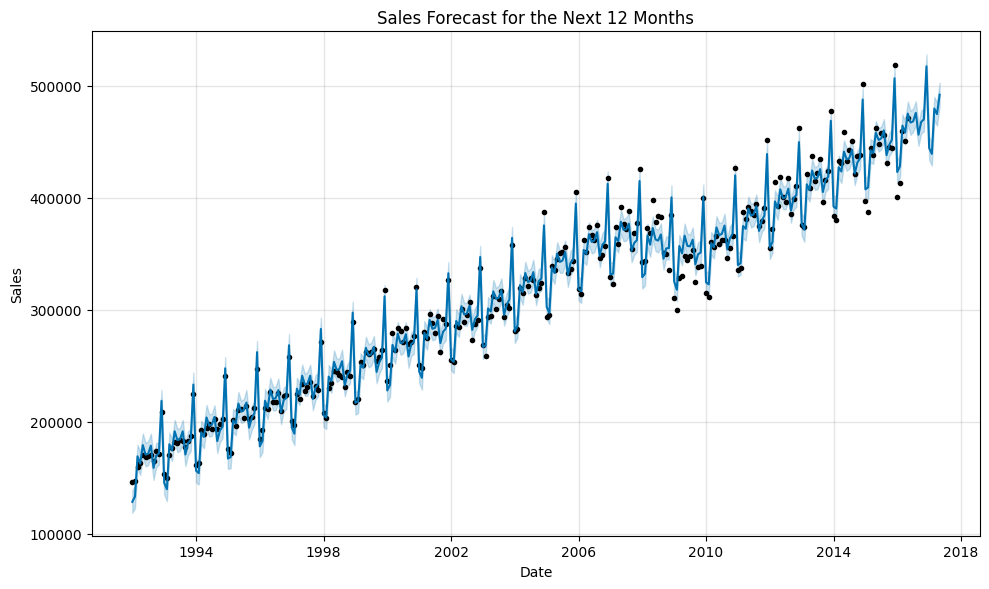

In [11]:
fig = model.plot(forecast)

plt.title("Sales Forecast for the Next 12 Months")
plt.xlabel("Date")
plt.ylabel("Sales")
plt.tight_layout()
plt.show()

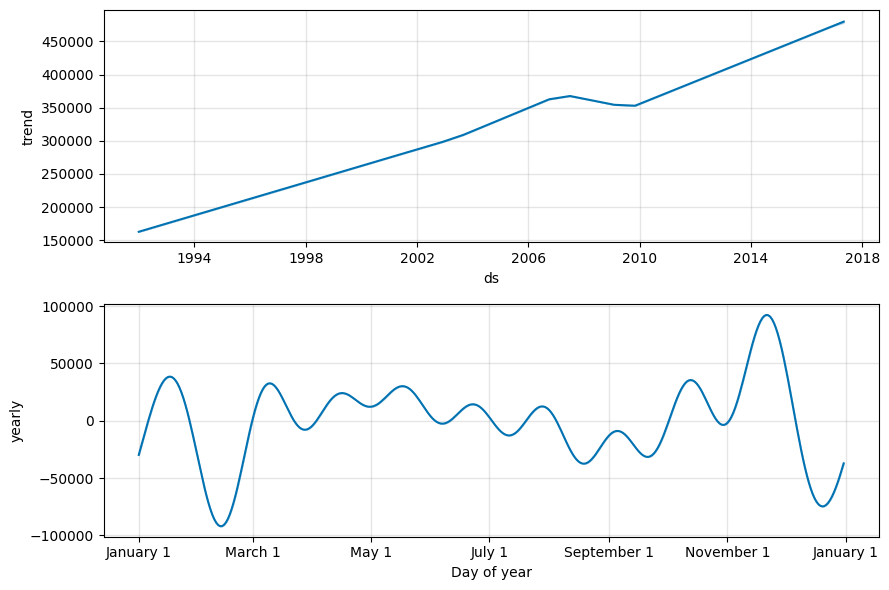

In [12]:
fig = model.plot_components(forecast)

plt.tight_layout()
plt.show()

In [13]:
import os

os.makedirs("results", exist_ok=True)

forecast_output = forecast[
    ["ds", "yhat", "yhat_lower", "yhat_upper"]
].copy()

forecast_output.to_csv("results/sales_forecast.csv", index=False)

print("Forecast saved to results/sales_forecast.csv")
display(forecast_output.tail(12))

Forecast saved to results/sales_forecast.csv


,ds,yhat,yhat_lower,yhat_upper
293,2016-06-01,467188.345347,456185.966473,477747.140292
294,2016-07-01,468248.724215,458809.847704,479718.773234
295,2016-08-01,475883.480448,464955.733289,486214.100776
296,2016-09-01,456400.254597,446381.091167,466320.099461
297,2016-10-01,467659.854258,457484.353642,478083.999687
298,2016-11-01,470096.501960,459113.392201,479786.390846
299,2016-12-01,517417.847284,507293.570853,528189.592829
300,2017-01-01,444482.347627,433956.119754,454493.323922
301,2017-02-01,439253.658387,428671.959339,449411.783211
302,2017-03-01,479736.961770,469346.415178,490238.726065


In [14]:
# Ensure the dataset is sorted chronologically
df = df[["ds", "y"]].copy()
df["ds"] = pd.to_datetime(df["ds"])
df["y"] = pd.to_numeric(df["y"], errors="coerce")
df = df.dropna().sort_values("ds").reset_index(drop=True)

split_index = int(len(df) * 0.8)

train_df = df.iloc[:split_index].copy()
test_df = df.iloc[split_index:].copy()

print("Training observations:", len(train_df))
print("Testing observations:", len(test_df))
print("Training period:", train_df["ds"].min(), "to", train_df["ds"].max())
print("Testing period:", test_df["ds"].min(), "to", test_df["ds"].max())

Training observations: 234
Testing observations: 59
Training period: 1992-01-01 00:00:00 to 2011-06-01 00:00:00
Testing period: 2011-07-01 00:00:00 to 2016-05-01 00:00:00


In [15]:
from prophet import Prophet

evaluation_model = Prophet(
    yearly_seasonality=True,
    weekly_seasonality=False,
    daily_seasonality=False
)

evaluation_model.fit(train_df)

print("Evaluation model trained successfully!")

Evaluation model trained successfully!


In [16]:
test_predictions = evaluation_model.predict(
    test_df[["ds"]]
)

evaluation_df = test_df.merge(
    test_predictions[["ds", "yhat", "yhat_lower", "yhat_upper"]],
    on="ds",
    how="left"
)

display(evaluation_df.head(10))

,ds,y,yhat,yhat_lower,yhat_upper
0,2011-07-01,384600,361498.538663,349698.357192,373858.444743
1,2011-08-01,394548,369269.404035,357228.122434,381025.844993
2,2011-09-01,374895,346644.537335,334322.802925,358868.273223
3,2011-10-01,379364,353620.592147,342384.811418,366011.571942
4,2011-11-01,391081,357223.967264,344869.636914,369838.881520
5,2011-12-01,451669,405463.161347,393253.473980,418313.408518
6,2012-01-01,355058,328909.157864,316148.042121,340274.925641
7,2012-02-01,372523,330253.842648,318546.873509,342662.383546
8,2012-03-01,414275,362178.165900,348981.080062,374876.770669
9,2012-04-01,393035,357242.331283,344827.564344,369438.885687


In [17]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

mae = mean_absolute_error(
    evaluation_df["y"],
    evaluation_df["yhat"]
)

rmse = np.sqrt(
    mean_squared_error(
        evaluation_df["y"],
        evaluation_df["yhat"]
    )
)

# MAPE is unreliable when actual sales are zero
nonzero_actuals = evaluation_df["y"] != 0

if nonzero_actuals.any():
    mape = (
        np.abs(
            (evaluation_df.loc[nonzero_actuals, "y"]
             - evaluation_df.loc[nonzero_actuals, "yhat"])
            / evaluation_df.loc[nonzero_actuals, "y"]
        ).mean() * 100
    )
else:
    mape = np.nan

print(f"MAE:  {mae:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"MAPE: {mape:.2f}%" if pd.notna(mape) else "MAPE: undefined")

MAE:  65673.60
RMSE: 69688.08
MAPE: 15.27%


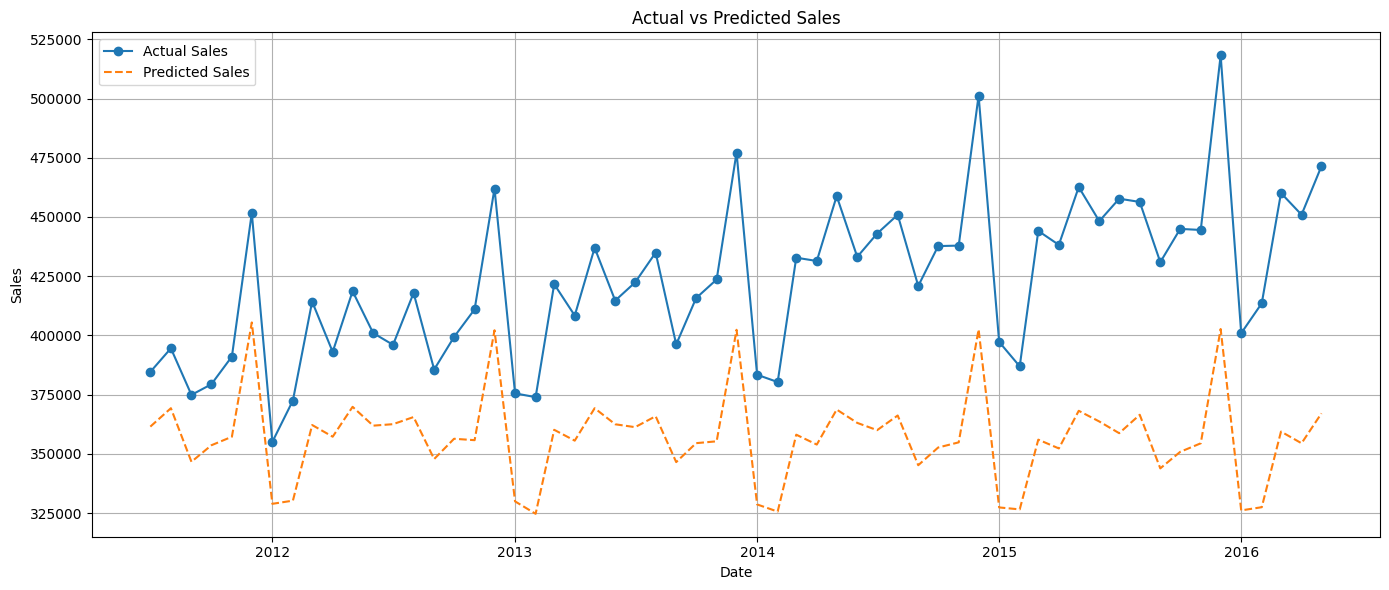

In [18]:
plt.figure(figsize=(14, 6))

plt.plot(
    evaluation_df["ds"],
    evaluation_df["y"],
    label="Actual Sales",
    marker="o"
)

plt.plot(
    evaluation_df["ds"],
    evaluation_df["yhat"],
    label="Predicted Sales",
    linestyle="--"
)

plt.title("Actual vs Predicted Sales")
plt.xlabel("Date")
plt.ylabel("Sales")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [19]:
import os

os.makedirs("results", exist_ok=True)

metrics_df = pd.DataFrame({
    "Metric": ["MAE", "RMSE", "MAPE"],
    "Value": [mae, rmse, mape]
})

metrics_df.to_csv("results/evaluation_metrics.csv", index=False)
evaluation_df.to_csv("results/test_predictions.csv", index=False)

print("Evaluation metrics:")
display(metrics_df)

print("Files saved successfully:")
print("- results/evaluation_metrics.csv")
print("- results/test_predictions.csv")

Evaluation metrics:


,Metric,Value
0,MAE,65673.604598
1,RMSE,69688.076459
2,MAPE,15.270744


Files saved successfully:
- results/evaluation_metrics.csv
- results/test_predictions.csv


In [20]:
import joblib

os.makedirs("models", exist_ok=True)

joblib.dump(
    evaluation_model,
    "models/prophet_sales_model.joblib"
)

print("Model saved to models/prophet_sales_model.joblib")

Model saved to models/prophet_sales_model.joblib


In [21]:
from pathlib import Path

for path in [
    "results/sales_forecast.csv",
    "results/evaluation_metrics.csv",
    "results/test_predictions.csv",
    "models/prophet_sales_model.joblib"
]:
    print(f"{'✓' if Path(path).exists() else '✗'} {path}")

✓ results/sales_forecast.csv
✓ results/evaluation_metrics.csv
✓ results/test_predictions.csv
✓ models/prophet_sales_model.joblib


In [22]:
from pathlib import Path

Path("README.md").write_text("""
# Sales Forecasting Using Prophet

## Project Overview
This project analyzes historical sales data and forecasts future sales
using the Prophet time-series forecasting model.

## Objectives
- Analyze historical sales trends.
- Visualize sales patterns over time.
- Forecast future sales.
- Compare actual sales with predicted sales.
- Evaluate the model using MAE, RMSE, and MAPE.

## Technologies Used
- Python
- Pandas and NumPy
- Matplotlib
- Facebook Prophet
- Scikit-learn
- Joblib

## Methodology
1. Load and inspect the sales dataset.
2. Clean missing and invalid values.
3. Visualize historical sales.
4. Train a Prophet forecasting model.
5. Generate future sales predictions.
6. Evaluate predictions on a chronological test set.
7. Save the forecast, evaluation metrics, and trained model.

## Evaluation Metrics
- MAE: Mean Absolute Error
- RMSE: Root Mean Squared Error
- MAPE: Mean Absolute Percentage Error

See `results/evaluation_metrics.csv` for the calculated values.

## Project Files
- `results/sales_forecast.csv`: Forecast output.
- `results/evaluation_metrics.csv`: Model evaluation metrics.
- `results/test_predictions.csv`: Actual and predicted test-period sales.
- `models/prophet_sales_model.joblib`: Saved forecasting model.

## Limitations
Forecast quality depends on the dataset's length, quality, and patterns.
Predictions are estimates and should not be treated as guaranteed sales.

## Author
CodeTech Internship Project
""", encoding="utf-8")

print("README.md created successfully!")

README.md created successfully!


In [23]:
from pathlib import Path

files_to_check = [
    "README.md",
    "results/sales_forecast.csv",
    "results/evaluation_metrics.csv",
    "results/test_predictions.csv",
    "models/prophet_sales_model.joblib"
]

for file in files_to_check:
    print(("✓ " if Path(file).exists() else "✗ "), file)

✓  README.md
✓  results/sales_forecast.csv
✓  results/evaluation_metrics.csv
✓  results/test_predictions.csv
✓  models/prophet_sales_model.joblib


In [24]:
import zipfile
from pathlib import Path

files_to_package = [
    "README.md",
    "results/sales_forecast.csv",
    "results/evaluation_metrics.csv",
    "results/test_predictions.csv",
    "models/prophet_sales_model.joblib"
]

missing = [f for f in files_to_package if not Path(f).exists()]

if missing:
    print("Missing files:", missing)
else:
    with zipfile.ZipFile(
        "sales_forecasting_project.zip",
        "w",
        zipfile.ZIP_DEFLATED
    ) as z:
        for file in files_to_package:
            z.write(file, arcname=file)

    print("ZIP created successfully!")

ZIP created successfully!


In [25]:
from google.colab import files
files.download("sales_forecasting_project.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>